In [3]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [6]:
import os
import shutil
import glob

DRIVE_DIR = "/content/drive/MyDrive/Processed_SP_ML"
LOCAL_DIR = "/content/Processed_SP_ML"
RESULTS_DIR = "/content/drive/MyDrive/CNN_results"

# Copy dataset from Google Drive to Colab
if not os.path.exists(LOCAL_DIR):
    shutil.copytree(DRIVE_DIR, LOCAL_DIR)

# Create results directory
os.makedirs(RESULTS_DIR, exist_ok=True)

# Count images
IMAGE_DIR = os.path.join(LOCAL_DIR, "images")

if not os.path.isdir(IMAGE_DIR):
    raise FileNotFoundError(f"Images folder not found: {IMAGE_DIR}")

print("Images:", len(os.listdir(IMAGE_DIR)))

# Find numbers-only prediction files in Google Drive
oof_matches = glob.glob(
    "/content/drive/MyDrive/**/oof_predictions_numbers_only.csv",
    recursive=True
)

test_matches = glob.glob(
    "/content/drive/MyDrive/**/test_predictions_numbers_only.csv",
    recursive=True
)

if not oof_matches:
    raise FileNotFoundError(
        "Could not find oof_predictions_numbers_only.csv in Google Drive. "
        "Upload it from your results_numbers_only folder."
    )

if not test_matches:
    raise FileNotFoundError(
        "Could not find test_predictions_numbers_only.csv in Google Drive. "
        "Upload it from your results_numbers_only folder."
    )

NUM_OOF = oof_matches[0]
NUM_TEST = test_matches[0]

print("Numbers-only CV file:  ", NUM_OOF)
print("Numbers-only test file:", NUM_TEST)

Images: 1032
Numbers-only CV file:   /content/drive/MyDrive/Processed_SP_ML/results_numbers_only/oof_predictions_numbers_only.csv
Numbers-only test file: /content/drive/MyDrive/Processed_SP_ML/results_numbers_only/test_predictions_numbers_only.csv


In [7]:
import json, time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             roc_curve, hamming_loss, accuracy_score)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NONE - turn on T4 GPU!")


device: cuda | GPU: Tesla T4


In [8]:
BACKBONE = "densenet121"

PRETRAINED = True
IMG_W, IMG_H = 384, 288
EPOCHS, WARMUP_EPOCHS, PATIENCE = 30, 2, 7
BATCH_SIZE = 16
LR_HEAD, LR_BACKBONE, WEIGHT_DECAY = 1e-3, 1e-4, 1e-4
SEED = 42
LABEL_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]

IMG_RUN   = os.path.join(RESULTS_DIR, f"image_only_{BACKBONE}")    # from notebook 05b
FUS_RUN   = os.path.join(RESULTS_DIR, f"fusion_{BACKBONE}")
FINAL_DIR = os.path.join(RESULTS_DIR, f"final_{BACKBONE}")
os.makedirs(FUS_RUN, exist_ok=True); os.makedirs(FINAL_DIR, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

man = pd.read_csv(os.path.join(LOCAL_DIR, "Image_Manifest_MultiLabel.csv"))
train_df = man[man["Split"] == "train"].reset_index(drop=True)
test_df  = man[man["Split"] == "test"].reset_index(drop=True)
N_FOLDS = int(train_df["CV_Fold"].max()) + 1
img_folds = json.load(open(os.path.join(IMG_RUN, "fold_info.json")))
print(f"{BACKBONE} | train {len(train_df)} | test {len(test_df)} | folds {N_FOLDS} | image-only folds found: {len(img_folds)}")
pd.DataFrame({"Train": train_df[LABEL_COLS].sum(), "Test": test_df[LABEL_COLS].sum()})


densenet121 | train 824 | test 208 | folds 5 | image-only folds found: 5


,Train,Test
FECD,101,25
Guttata,81,19
Folds,306,74
PolyPleo,105,26
LowCD,102,23


In [9]:
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
T = torchvision.transforms
TF_TRAIN = T.Compose([T.ToPILImage(),
                      T.RandomResizedCrop((IMG_H, IMG_W), scale=(0.7, 1.0), ratio=(1.25, 1.42)),
                      T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(15),
                      T.ColorJitter(brightness=0.2, contrast=0.2),
                      T.Grayscale(3), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])
TF_EVAL = T.Compose([T.ToPILImage(), T.Resize((IMG_H, IMG_W)),
                     T.Grayscale(3), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])

def fit_tab_scaler(frame):
    """Median-impute + standardise the 6 numbers using the TRAINING rows only."""
    imp = SimpleImputer(strategy="median").fit(frame[FEATURES])
    sc = StandardScaler().fit(imp.transform(frame[FEATURES]))
    return lambda f: sc.transform(imp.transform(f[FEATURES])).astype(np.float32)

class SPDataset(Dataset):
    def __init__(self, frame, tab, train):
        self.paths = [os.path.join(LOCAL_DIR, "images", f) for f in frame["Proc_File"]]
        self.Y = frame[LABEL_COLS].values.astype(np.float32)
        self.tab = torch.tensor(tab, dtype=torch.float32)
        self.tf = TF_TRAIN if train else TF_EVAL
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(cv2.imread(self.paths[i], cv2.IMREAD_GRAYSCALE)), self.tab[i], torch.tensor(self.Y[i])

def make_backbone(name, pretrained):
    W = "DEFAULT" if pretrained else None
    if name == "densenet121":
        m = models.densenet121(weights=W); dim = m.classifier.in_features; m.classifier = nn.Identity(); cam = m.features
    elif name in ("efficientnet_b0", "efficientnet_b2"):
        m = getattr(models, name)(weights=W); dim = m.classifier[1].in_features; m.classifier = nn.Identity(); cam = m.features[-1]
    elif name == "resnet50":
        m = models.resnet50(weights=W); dim = m.fc.in_features; m.fc = nn.Identity(); cam = m.layer4
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=W); dim = m.classifier[2].in_features; m.classifier[2] = nn.Identity(); cam = m.features[-1]
    else:
        raise ValueError(name)
    return m, dim, cam

class ImageOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, dim, self.cam_layer = make_backbone(BACKBONE, PRETRAINED)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim, len(LABEL_COLS)))
    def forward(self, x, tab=None):
        return self.head(self.backbone(x))

class Fusion(nn.Module):
    """CNN image features + small network on the 6 numbers -> joined -> 5 disease outputs."""
    def __init__(self):
        super().__init__()
        self.backbone, dim, self.cam_layer = make_backbone(BACKBONE, PRETRAINED)
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2),
                                     nn.Linear(32, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, len(LABEL_COLS)))
    def forward(self, x, tab):
        return self.head(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))

print("OK - image-only and fusion models defined")


OK - image-only and fusion models defined


In [10]:
def pos_weight(Y):
    pos = Y.sum(0); neg = len(Y) - pos
    return torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32, device=DEVICE)

def make_loader(frame, scale, train):
    return DataLoader(SPDataset(frame, scale(frame), train), batch_size=BATCH_SIZE if train else 32,
                      shuffle=train, drop_last=train, num_workers=2, pin_memory=True)

@torch.no_grad()
def predict(model, dl):
    model.eval(); out = []
    for x, tab, _ in dl:
        x, tab = x.to(DEVICE), tab.to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            p = torch.sigmoid(model(x, tab)) + torch.sigmoid(model(torch.flip(x, dims=[3]), tab))
        out.append((p / 2).float().cpu().numpy())
    return np.concatenate(out)

def macro_auc(Y, P):
    return np.mean([roc_auc_score(Y[:, j], P[:, j]) for j in range(Y.shape[1]) if 0 < Y[:, j].sum() < len(Y)])

def train_one(ModelCls, tr_frame, va_frame=None, epochs=EPOCHS, log=True):
    set_seed()
    scale = fit_tab_scaler(tr_frame)
    tr_dl = make_loader(tr_frame, scale, True)
    va_dl = None if va_frame is None else make_loader(va_frame, scale, False)
    model = ModelCls().to(DEVICE)
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight(tr_frame[LABEL_COLS].values))
    opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": LR_BACKBONE},
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs - WARMUP_EPOCHS, 1))
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
    best, best_auc, best_ep, wait = None, -1, epochs, 0
    for ep in range(1, epochs + 1):
        warm = ep <= WARMUP_EPOCHS
        for p in model.backbone.parameters(): p.requires_grad = not warm
        model.train(); t0, losses = time.time(), []
        for x, tab, y in tr_dl:
            x, tab, y = x.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = crit(model(x, tab), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); losses.append(loss.item())
        if not warm: sched.step()
        msg = f"  ep {ep:2d} loss {np.mean(losses):.4f}"
        if va_dl is not None:
            a = macro_auc(va_frame[LABEL_COLS].values, predict(model, va_dl)); msg += f" | val macro-AUC {a:.3f}"
            if a > best_auc: best_auc, best_ep, best, wait = a, ep, copy.deepcopy(model.state_dict()), 0
            elif not warm: wait += 1
        if log: print(msg + (" (warm-up)" if warm else "") + f" ({time.time() - t0:.0f}s)")
        if va_dl is not None and wait >= PATIENCE: break
    if best is not None: model.load_state_dict(best)
    for p in model.parameters(): p.requires_grad = True
    return model, scale, best_ep

print("OK - training functions ready")


OK - training functions ready


In [11]:
oof_path, info_path = os.path.join(FUS_RUN, "oof_predictions.csv"), os.path.join(FUS_RUN, "fold_info.json")
oof = pd.read_csv(oof_path) if os.path.exists(oof_path) else \
      train_df[["Tissue_ID", "CV_Fold"] + LABEL_COLS].assign(**{f"P_{l}": np.nan for l in LABEL_COLS})
fus_folds = json.load(open(info_path)) if os.path.exists(info_path) else {}

for k in range(N_FOLDS):
    if str(k) in fus_folds:
        print(f"Fold {k} already done (val macro-AUC {fus_folds[str(k)]['val_macro_auc']:.3f}) - skipping"); continue
    tr_f, va_f = train_df[train_df["CV_Fold"] != k], train_df[train_df["CV_Fold"] == k]
    print(f"\n===== Fusion {BACKBONE} | fold {k} | train {len(tr_f)} / val {len(va_f)} =====")
    t0 = time.time()
    model, scale, best_ep = train_one(Fusion, tr_f, va_f)
    P = predict(model, make_loader(va_f, scale, False))
    oof.loc[oof["Tissue_ID"].isin(va_f["Tissue_ID"]), [f"P_{l}" for l in LABEL_COLS]] = P
    oof.to_csv(oof_path, index=False)
    fus_folds[str(k)] = {"best_epoch": int(best_ep), "val_macro_auc": float(macro_auc(va_f[LABEL_COLS].values, P)),
                         "minutes": round((time.time() - t0) / 60, 1)}
    json.dump(fus_folds, open(info_path, "w"), indent=2)
    print(f"Fold {k}: val macro-AUC {fus_folds[str(k)]['val_macro_auc']:.3f}, best epoch {best_ep} - SAVED to Drive")
    del model; torch.cuda.empty_cache()



===== Fusion densenet121 | fold 0 | train 660 / val 164 =====
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 121MB/s]


  ep  1 loss 1.1458 | val macro-AUC 0.756 (warm-up) (12s)
  ep  2 loss 1.0433 | val macro-AUC 0.860 (warm-up) (10s)
  ep  3 loss 0.8004 | val macro-AUC 0.869 (12s)
  ep  4 loss 0.6397 | val macro-AUC 0.910 (10s)
  ep  5 loss 0.5729 | val macro-AUC 0.920 (12s)
  ep  6 loss 0.5268 | val macro-AUC 0.920 (12s)
  ep  7 loss 0.5002 | val macro-AUC 0.922 (11s)
  ep  8 loss 0.4760 | val macro-AUC 0.924 (11s)
  ep  9 loss 0.4616 | val macro-AUC 0.922 (12s)
  ep 10 loss 0.4367 | val macro-AUC 0.920 (12s)
  ep 11 loss 0.4507 | val macro-AUC 0.908 (13s)
  ep 12 loss 0.4397 | val macro-AUC 0.917 (10s)
  ep 13 loss 0.4076 | val macro-AUC 0.921 (12s)
  ep 14 loss 0.3544 | val macro-AUC 0.917 (12s)
  ep 15 loss 0.3548 | val macro-AUC 0.914 (11s)
Fold 0: val macro-AUC 0.924, best epoch 8 - SAVED to Drive

===== Fusion densenet121 | fold 1 | train 657 / val 167 =====
  ep  1 loss 1.1723 | val macro-AUC 0.790 (warm-up) (8s)
  ep  2 loss 1.0576 | val macro-AUC 0.874 (warm-up) (9s)
  ep  3 loss 0.8321 | va

In [12]:
def load_oof(path, ids):
    o = pd.read_csv(path).drop_duplicates("Tissue_ID").set_index("Tissue_ID").loc[ids]
    return o[LABEL_COLS].values, o[[f"P_{l}" for l in LABEL_COLS]].values

ids = list(train_df["Tissue_ID"])
OOF = {"Numbers only":    load_oof(NUM_OOF, ids),
       "Image only":      load_oof(os.path.join(IMG_RUN, "oof_predictions.csv"), ids),
       "Image + numbers": load_oof(oof_path, ids)}

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p); return float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))
THRESH = {name: {lab: youden(Y[:, j], P[:, j]) for j, lab in enumerate(LABEL_COLS)} for name, (Y, P) in OOF.items()}

cv_auc = pd.DataFrame({name: {lab: roc_auc_score(Y[:, j], P[:, j]) for j, lab in enumerate(LABEL_COLS)}
                       for name, (Y, P) in OOF.items()}).T
cv_auc["Macro AUC"] = cv_auc.mean(axis=1)
cv_auc.to_csv(os.path.join(FINAL_DIR, "cv_auc_comparison.csv"))
print(f"TRAIN CV ROC-AUC per disease - {BACKBONE} (identical donor-grouped folds)")
cv_auc.round(3)


TRAIN CV ROC-AUC per disease - densenet121 (identical donor-grouped folds)


,FECD,Guttata,Folds,PolyPleo,LowCD,Macro AUC
Numbers only,0.983,0.554,0.633,0.963,0.971,0.821
Image only,0.868,0.844,0.814,0.856,0.876,0.852
Image + numbers,0.974,0.857,0.860,0.976,0.979,0.929


In [13]:
final_models, P_TEST = {}, {}
for name, Cls, folds_info in [("Image only", ImageOnly, img_folds), ("Image + numbers", Fusion, fus_folds)]:
    ep = max(int(np.median([v["best_epoch"] for v in folds_info.values()])), WARMUP_EPOCHS + 1)
    print(f"\n--- Final {name}: {ep} epochs on all {len(train_df)} train images")
    model, scale, _ = train_one(Cls, train_df, None, epochs=ep)
    P_TEST[name] = predict(model, make_loader(test_df, scale, False))
    final_models[name] = (model, scale)
    torch.save(model.state_dict(), os.path.join(FINAL_DIR, f"{name.replace(' ', '_').replace('+', 'plus')}.pt"))

num_te = pd.read_csv(NUM_TEST).drop_duplicates("Tissue_ID").set_index("Tissue_ID")
P_TEST["Numbers only"] = num_te.loc[test_df["Tissue_ID"], [f"P_{l}" for l in LABEL_COLS]].values
Y_TE = test_df[LABEL_COLS].values
print("\nOK - test predictions ready for all 3 configurations")



--- Final Image only: 7 epochs on all 824 train images
  ep  1 loss 1.1748 (warm-up) (8s)
  ep  2 loss 1.1219 (warm-up) (7s)
  ep  3 loss 1.0236 (12s)
  ep  4 loss 0.9096 (12s)
  ep  5 loss 0.7889 (11s)
  ep  6 loss 0.7245 (10s)
  ep  7 loss 0.6921 (12s)

--- Final Image + numbers: 11 epochs on all 824 train images
  ep  1 loss 1.1401 (warm-up) (9s)
  ep  2 loss 0.9575 (warm-up) (7s)
  ep  3 loss 0.7468 (12s)
  ep  4 loss 0.6138 (17s)
  ep  5 loss 0.5267 (11s)
  ep  6 loss 0.5338 (11s)
  ep  7 loss 0.4697 (10s)
  ep  8 loss 0.4749 (12s)
  ep  9 loss 0.4590 (12s)
  ep 10 loss 0.4312 (12s)
  ep 11 loss 0.4122 (11s)

OK - test predictions ready for all 3 configurations


In [14]:
def evaluate(Y, P, thr):
    pred = (P >= np.array([thr[l] for l in LABEL_COLS])).astype(int)
    per = pd.DataFrame({lab: {"ROC_AUC": roc_auc_score(Y[:, j], P[:, j]),
                              "PR_AUC": average_precision_score(Y[:, j], P[:, j]),
                              "F1": f1_score(Y[:, j], pred[:, j], zero_division=0),
                              "Sensitivity": recall_score(Y[:, j], pred[:, j], zero_division=0),
                              "Specificity": recall_score(Y[:, j], pred[:, j], pos_label=0, zero_division=0)}
                        for j, lab in enumerate(LABEL_COLS)}).T
    normal = (Y.sum(1) == 0).astype(int)
    overall = {"Macro ROC-AUC": per["ROC_AUC"].mean(), "Macro F1": f1_score(Y, pred, average="macro", zero_division=0),
               "Hamming loss": hamming_loss(Y, pred), "Exact match": accuracy_score(Y, pred),
               "Normal-vs-disease AUC": roc_auc_score(1 - normal, P.max(1))}
    return per, overall, pred

ORDER = ["Numbers only", "Image only", "Image + numbers"]
test_auc, overall_tab, PRED, PER = {}, {}, {}, {}
for name in ORDER:
    PER[name], overall_tab[name], PRED[name] = evaluate(Y_TE, P_TEST[name], THRESH[name])
    test_auc[name] = PER[name]["ROC_AUC"]
    PER[name].to_csv(os.path.join(FINAL_DIR, f"test_metrics_{name.replace(' ', '_').replace('+', 'plus')}.csv"))
test_auc = pd.DataFrame(test_auc).T; test_auc["Macro AUC"] = test_auc.mean(axis=1)
test_auc.to_csv(os.path.join(FINAL_DIR, "test_auc_comparison.csv"))

print("HELD-OUT TEST ROC-AUC per disease"); display(test_auc.round(3))
print("Overall (test)"); display(pd.DataFrame(overall_tab).round(3))
print("Image + numbers - full per-disease test metrics"); display(PER["Image + numbers"].round(3))

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(Y_TE), len(Y_TE)) for _ in range(1000)]
ci = {}
for name in ORDER:
    ci[name] = {}
    for j, lab in enumerate(LABEL_COLS):
        s = [roc_auc_score(Y_TE[i, j], P_TEST[name][i, j]) for i in boot_idx if 0 < Y_TE[i, j].sum() < len(i)]
        ci[name][lab] = f"{test_auc.loc[name, lab]:.2f} [{np.percentile(s, 2.5):.2f}-{np.percentile(s, 97.5):.2f}]"
ci_table = pd.DataFrame(ci).T
ci_table.to_csv(os.path.join(FINAL_DIR, "test_auc_ci.csv"))
print("Test ROC-AUC [95% bootstrap CI]"); ci_table


HELD-OUT TEST ROC-AUC per disease


,FECD,Guttata,Folds,PolyPleo,LowCD,Macro AUC
Numbers only,0.991,0.617,0.648,0.991,0.958,0.841
Image only,0.909,0.875,0.835,0.896,0.916,0.886
Image + numbers,0.990,0.872,0.866,0.990,0.978,0.939


Overall (test)


,Numbers only,Image only,Image + numbers
Macro ROC-AUC,0.841,0.886,0.939
Macro F1,0.649,0.537,0.731
Hamming loss,0.241,0.189,0.108
Exact match,0.154,0.514,0.611
Normal-vs-disease AUC,0.690,0.848,0.853


Image + numbers - full per-disease test metrics


,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity
FECD,0.990,0.902,0.877,1.000,0.962
Guttata,0.872,0.736,0.484,0.789,0.852
Folds,0.866,0.714,0.729,0.838,0.746
PolyPleo,0.990,0.904,0.812,1.000,0.934
LowCD,0.978,0.728,0.754,1.000,0.919


Test ROC-AUC [95% bootstrap CI]


,FECD,Guttata,Folds,PolyPleo,LowCD
Numbers only,0.99 [0.98-1.00],0.62 [0.47-0.76],0.65 [0.57-0.72],0.99 [0.98-1.00],0.96 [0.90-0.99]
Image only,0.91 [0.84-0.96],0.87 [0.75-0.96],0.83 [0.78-0.89],0.90 [0.82-0.96],0.92 [0.86-0.96]
Image + numbers,0.99 [0.98-1.00],0.87 [0.73-0.98],0.87 [0.81-0.91],0.99 [0.98-1.00],0.98 [0.96-0.99]


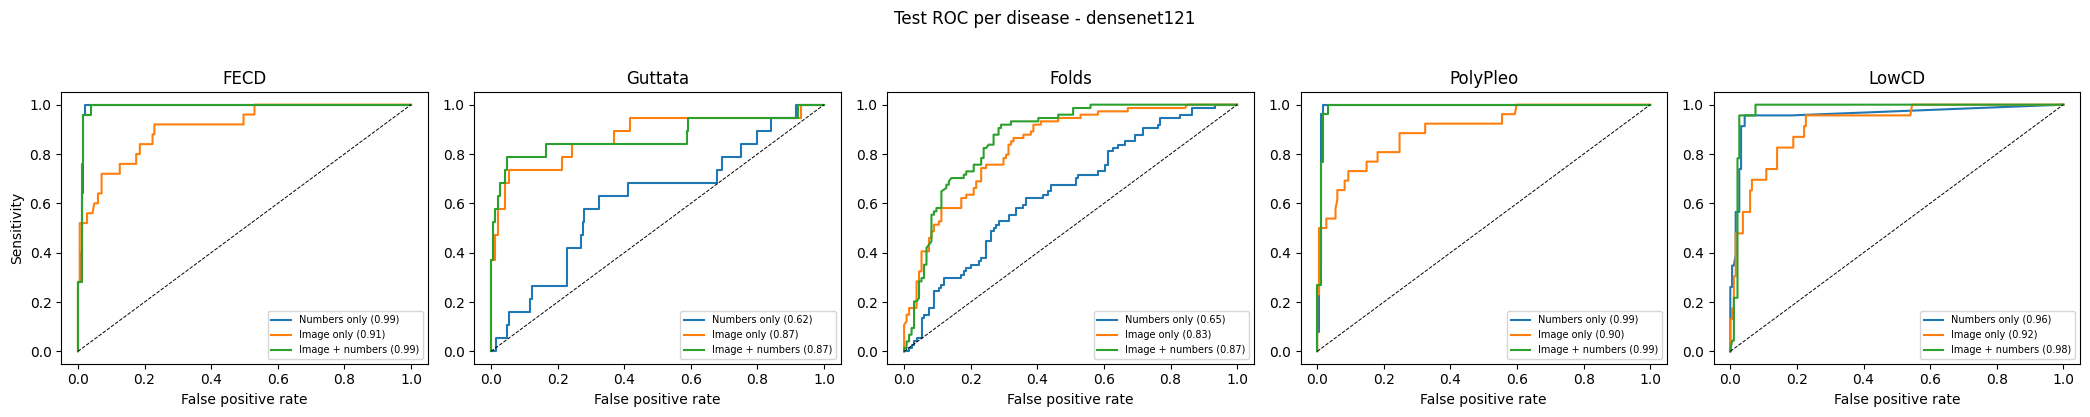

In [15]:
fig, axes = plt.subplots(1, len(LABEL_COLS), figsize=(4.2 * len(LABEL_COLS), 4))
for j, lab in enumerate(LABEL_COLS):
    for name in ORDER:
        fpr, tpr, _ = roc_curve(Y_TE[:, j], P_TEST[name][:, j])
        axes[j].plot(fpr, tpr, label=f"{name} ({test_auc.loc[name, lab]:.2f})")
    axes[j].plot([0, 1], [0, 1], "k--", lw=0.7)
    axes[j].set(title=lab, xlabel="False positive rate"); axes[j].legend(fontsize=7)
axes[0].set_ylabel("Sensitivity")
plt.suptitle(f"Test ROC per disease - {BACKBONE}", y=1.03); plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "test_roc.png"), dpi=120, bbox_inches="tight"); plt.show()


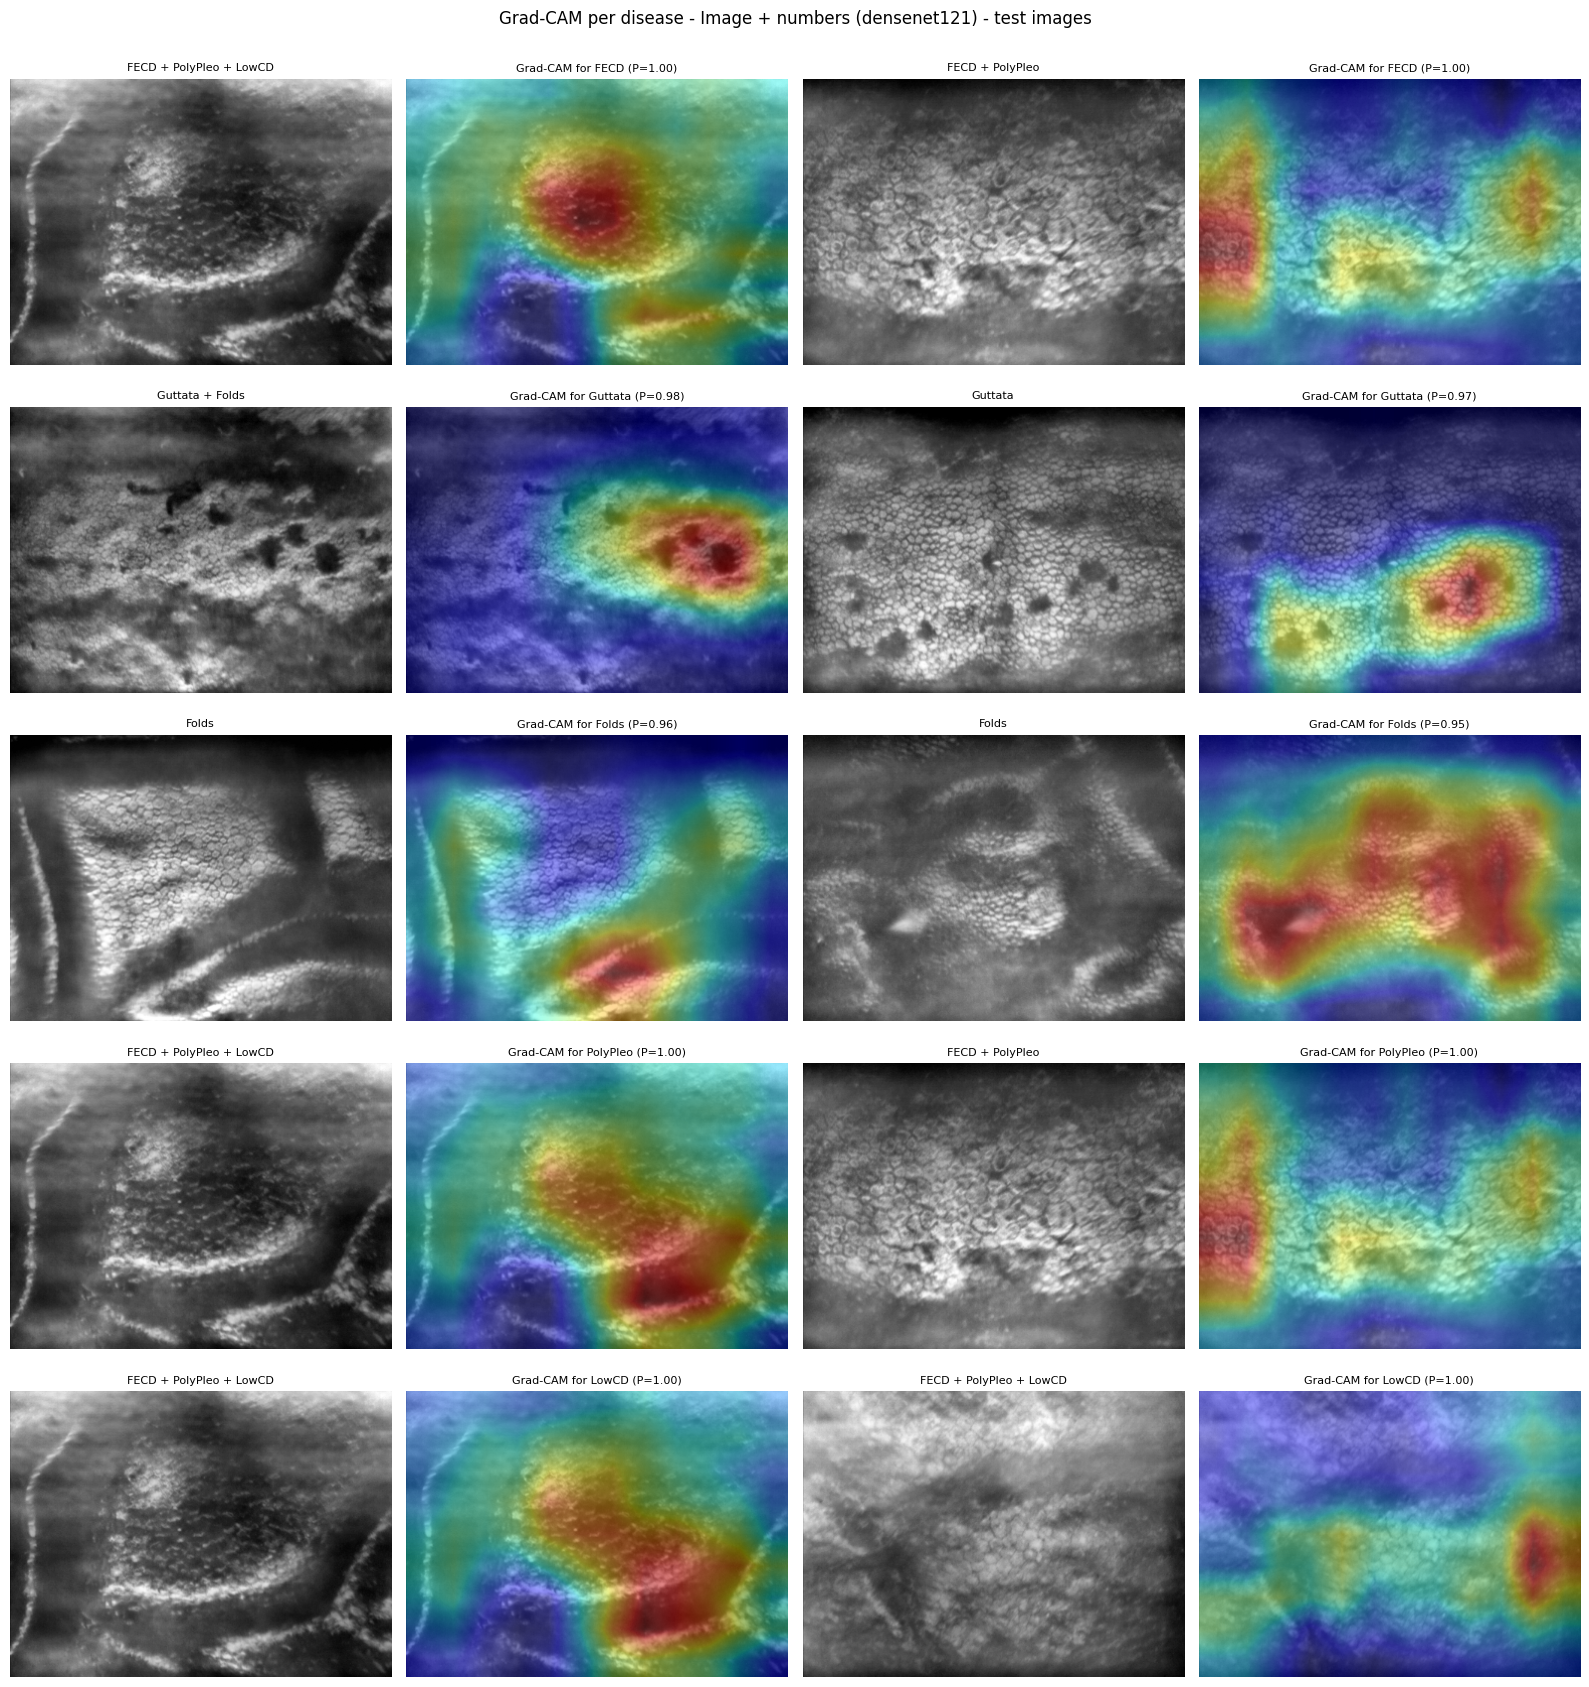

In [16]:
class GradCAM:
    def __init__(self, model):
        self.model, self.acts, self.grads = model.eval(), None, None
        def hook(m, i, o):
            self.acts = o; o.register_hook(lambda g: setattr(self, "grads", g))
        self.h = model.cam_layer.register_forward_hook(hook)
    def __call__(self, x, tab, label_idx):
        self.model.zero_grad()
        logit = self.model(x, tab)[0, label_idx]; logit.backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(1)).squeeze().detach().float().cpu().numpy()
        cam = cv2.resize(cam, (IMG_W, IMG_H))
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), torch.sigmoid(logit).item()
    def remove(self): self.h.remove()

CAM_MODEL = "Image + numbers" if test_auc.loc["Image + numbers", "Macro AUC"] >= test_auc.loc["Image only", "Macro AUC"] else "Image only"
model, scale = final_models[CAM_MODEL]
ds = SPDataset(test_df, scale(test_df), False)
gc = GradCAM(model); P = P_TEST[CAM_MODEL]

fig, axes = plt.subplots(len(LABEL_COLS), 4, figsize=(16, 3.4 * len(LABEL_COLS)))
for j, lab in enumerate(LABEL_COLS):
    pos = np.where(Y_TE[:, j] == 1)[0]
    for c, i in enumerate(pos[np.argsort(-P[pos, j])][:2]):          # 2 most confident true cases per disease
        x, tab, _ = ds[i]
        cam, p = gc(x.unsqueeze(0).to(DEVICE), tab.unsqueeze(0).to(DEVICE), j)
        raw = cv2.resize(cv2.imread(ds.paths[i], 0), (IMG_W, IMG_H))
        axes[j, 2 * c].imshow(raw, cmap="gray"); axes[j, 2 * c].set_title(test_df.loc[i, "Combination"], fontsize=8)
        axes[j, 2 * c + 1].imshow(raw, cmap="gray"); axes[j, 2 * c + 1].imshow(cam, cmap="jet", alpha=0.4)
        axes[j, 2 * c + 1].set_title(f"Grad-CAM for {lab} (P={p:.2f})", fontsize=8)
    for a in axes[j]: a.axis("off")
gc.remove()
plt.suptitle(f"Grad-CAM per disease - {CAM_MODEL} ({BACKBONE}) - test images", y=1.0); plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "gradcam_per_disease.png"), dpi=110, bbox_inches="tight"); plt.show()


In [17]:
out = test_df[["Tissue_ID", "Donor_Group", "Combination"] + LABEL_COLS].copy()
for name, tag in [("Numbers only", "Num"), ("Image only", "Img"), ("Image + numbers", "Fus")]:
    for j, lab in enumerate(LABEL_COLS):
        out[f"P_{tag}_{lab}"] = P_TEST[name][:, j]; out[f"Pred_{tag}_{lab}"] = PRED[name][:, j]
out.to_csv(os.path.join(FINAL_DIR, "test_predictions_all.csv"), index=False)

json.dump({"backbone": BACKBONE, "thresholds": THRESH,
           "cv_auc": cv_auc.round(4).to_dict(orient="index"),
           "test_auc": test_auc.round(4).to_dict(orient="index"),
           "test_overall": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in overall_tab.items()},
           "image_only_epochs": [v["best_epoch"] for v in img_folds.values()],
           "fusion_epochs": [v["best_epoch"] for v in fus_folds.values()]},
          open(os.path.join(FINAL_DIR, "summary_final.json"), "w"), indent=2)
print("Saved everything to", FINAL_DIR)
print(os.listdir(FINAL_DIR))


Saved everything to /content/drive/MyDrive/CNN_results/final_densenet121
['cv_auc_comparison.csv', 'Image_only.pt', 'Image_plus_numbers.pt', 'test_metrics_Numbers_only.csv', 'test_metrics_Image_only.csv', 'test_metrics_Image_plus_numbers.csv', 'test_auc_comparison.csv', 'test_auc_ci.csv', 'test_roc.png', 'gradcam_per_disease.png', 'test_predictions_all.csv', 'summary_final.json']
